# MERFISH hypothalamus: real and permuted gene variograms

Select 10 non-blank genes without replacement (seed 42). CPM uses each cell's total across **all non-blank genes**, not just the selected ten. Drop cells with zero non-blank total or non-finite spatial coordinates. Expression is the natural logarithm, \(X_{ig}=\log(1+10^6 C_{ig}/\sum_{h\notin\mathrm{blanks}}C_{ih})\).

Each gene receives one independent, reproducible permutation of its **normalized expression** across the fixed spatial locations. Real and permuted spatial maps share a color scale within each gene.

For every unordered pair \(i<j\), compute Euclidean distance in the dataset's original coordinate units. Set \(d_{\max}=Q_{0.25}(\{d_{ij}:i<j\})\), using all retained cells and exact distances (no pair sampling). This is the distance quantile, **not** 25% of the maximum distance.

Use the default bin construction from [geoR 1.9-5 source](https://github.com/cran/geoR/blob/1.9-5/R/variogram.R): **13 equal-width intervals (14 edges)** and arithmetic bin midpoints. This differs from the 13-center description in the help text and from the earlier half-width endpoint bins in this notebook.

The cutoff is the exact 25th percentile of all unordered pairwise distances. As in geoR, bin construction ends at the largest observed distance strictly below that cutoff. The difference is less than one observed distance gap. Boundaries are \(0,U/13,\ldots,U\), where \(U=\max\{d_{ij}:d_{ij}<Q_{0.25}(d)\}\). geoR's empty near-zero bin is omitted; the first retained lower boundary is \(10^{-12}\). The data have no coincident locations. Following geoR's binit, intervals are left-closed and right-open, excluding the upper endpoint.

In every bin, \(\widehat\gamma_g(k)=\sum_{(i,j)\in N_k}(X_{ig}-X_{jg})^2/(2|N_k|)\). Bins with fewer than two pairs remain missing. Every figure and candidate fit uses the same all-cell pair assignments. The implementation remains entirely Python.

## Python variogram matching on all cells

All candidates use the preceding cell's pair assignments, 13 geoR-style bins, and bin midpoints. The candidate grid is `nn = 0, 0.05, 0.1, ..., 0.9`.

For positive `nn`, let \(h_i\) be the distance to the `ceil(nn*(N-1))`-th other cell. Degree-zero smoothing is a normalized weighted average of the fixed permutation, with weights \(w_{ij}\propto\exp[-(2.5d_{ij}/h_i)^2/2]\). The Gaussian standard deviation is **h_i/2.5**, following locfit's [Gaussian weight](https://github.com/cran/locfit/blob/master/src/weight.c) and [GFACT definition](https://github.com/cran/locfit/blob/master/src/local.h). Coordinates are not standardized. This Python implementation evaluates the weighted average directly at every cell; it does not reproduce locfit's evaluation-tree interpolation or exact neighbor-count rounding. R is not a runtime dependency.

Following the [STCompare matching pipeline](https://github.com/JEFworks-Lab/STcompare/blob/2983c99e485feb1665a489d97558026a448186c4/R/spatialCorrelation.R), regress the real variogram on each smoothed variogram with an intercept, construct `sqrt(abs(slope))*smooth + sqrt(abs(intercept))*noise`, and select the minimum empirical variogram SSE. This retains STCompare's absolute-value coefficient handling. Each gene uses a reproducible NumPy noise stream with seed 1, advanced across positive candidates. The `nn=0` candidate remains the exact permutation without regression or added noise.

The first matching cell shows candidates and selects `nn` **before final normalization**. Afterwards, each selected matched field is shifted and scaled to the real gene's mean and population standard deviation:

\[
Y_{\mathrm{final}}=\mu_X+\frac{\sigma_X}{\sigma_Y}(Y-\mu_Y).
\]

This final normalization is an additional step requested for this notebook, not STCompare's matching procedure. It does not reselect `nn`. The second matching cell recomputes the final variogram, reports SSE before and after normalization, and plots the normalized winner. Fields are not clipped or rank-remapped and can still contain negative values. The exact permutation baseline already has the target moments and is left unchanged.

The final spatial plots show true data, permutation, raw optimal blur, and the normalized final match. True, permuted, and final fields share a per-gene color scale. The raw blur has its own labeled color scale to reveal its small-amplitude spatial variation.


In [1]:
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist
from IPython.display import display

SEED = 42
N_GENES = 10
N_BINS = 13

# Locate the data whether this notebook is launched from notebooks/ or the repo root.
root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data/h5ad/merfish_hypothalamus.h5ad").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Launch from the repository root or its notebooks directory.")
adata = ad.read_h5ad(root / "data/h5ad/merfish_hypothalamus.h5ad")
nonblank = ~adata.var_names.str.contains("blank", case=False, regex=False)
counts = adata.X[:, nonblank].astype(np.float64)
gene_names = np.asarray(adata.var_names[nonblank], dtype=str)
values = counts.data if sparse.issparse(counts) else counts
if not np.isfinite(values).all() or np.any(values < 0):
    raise ValueError("Expected finite, nonnegative raw counts.")
if not np.allclose(values, np.round(values)):
    raise ValueError("adata.X does not appear to contain raw integer counts.")

coords_all = np.asarray(adata.obsm["spatial"], dtype=np.float64)
if coords_all.shape != (adata.n_obs, 2):
    raise ValueError("Expected two-dimensional spatial coordinates.")
library_size = np.asarray(counts.sum(axis=1)).ravel()
keep_cells = (library_size > 0) & np.isfinite(coords_all).all(axis=1)
coords = coords_all[keep_cells]
counts = counts[keep_cells]
library_size = library_size[keep_cells]
if len(coords) < 3 or len(gene_names) < N_GENES:
    raise ValueError("Not enough cells or non-blank genes.")

selected_columns = np.random.default_rng(SEED).choice(
    len(gene_names), size=N_GENES, replace=False
)
selected_genes = gene_names[selected_columns]
selected_counts = counts[:, selected_columns]
if sparse.issparse(selected_counts):
    selected_counts = selected_counts.toarray()
log_cpm = np.log1p(1e6 * selected_counts / library_size[:, None])

# Separate random streams make each gene's shuffle independent and reproducible.
permuted_log_cpm = np.column_stack([
    np.random.default_rng(seed).permutation(log_cpm[:, j])
    for j, seed in enumerate(np.random.SeedSequence(SEED + 1).spawn(N_GENES))
])
assert np.array_equal(
    np.sort(log_cpm, axis=0), np.sort(permuted_log_cpm, axis=0)
)
print(f"Retained {len(coords):,}/{adata.n_obs:,} cells; "
      f"excluded {(~keep_cells).sum()} zero-library/non-finite-coordinate cells.")
print(f"CPM denominator: all {len(gene_names)} non-blank genes.")
print("Selected genes:", ", ".join(selected_genes))


Retained 6,110/6,111 cells; excluded 1 zero-library/non-finite-coordinate cells.
CPM denominator: all 135 non-blank genes.
Selected genes: Traf4, Pnoc, Bdnf, Ntng1, Glra3, Tiparp, Oxtr, Bmp7, Cplx3, Sgk1


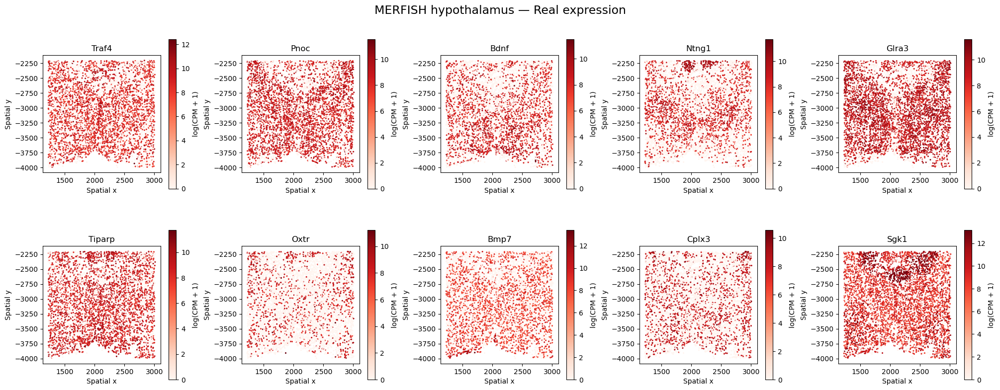

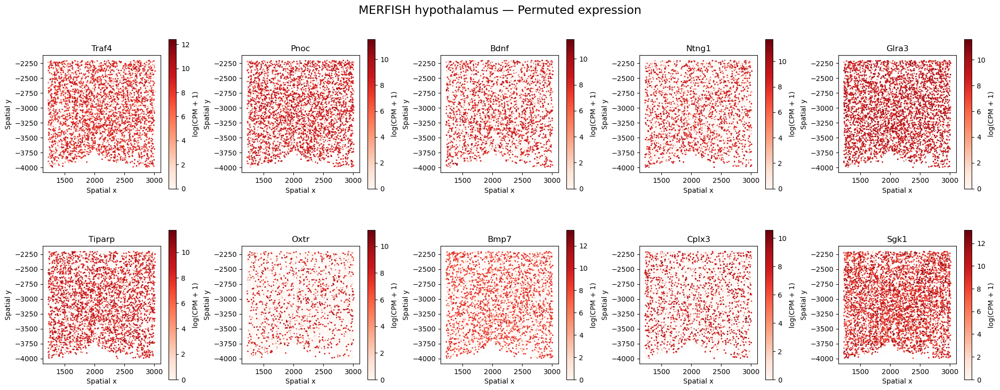

In [2]:
# Real and permuted maps use the same locations and per-gene color limits.
for label, expression in (("Real", log_cpm), ("Permuted", permuted_log_cpm)):
    fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
    for j, (ax, gene) in enumerate(zip(axes.flat, selected_genes)):
        points = ax.scatter(
            coords[:, 0], coords[:, 1], c=expression[:, j],
            cmap="Reds", vmin=0, vmax=max(log_cpm[:, j].max(), 1e-12),
            s=5, linewidths=0, rasterized=True,
        )
        ax.set(title=gene, xlabel="Spatial x", ylabel="Spatial y")
        ax.set_aspect("equal", adjustable="box")
        fig.colorbar(points, ax=ax, shrink=0.8, label="log(CPM + 1)")
    fig.suptitle(f"MERFISH hypothalamus — {label} expression", fontsize=17)
    plt.show()


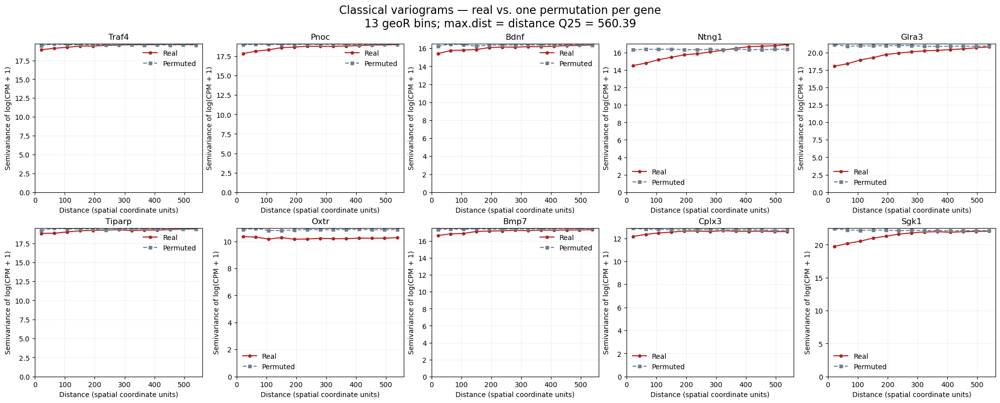

max.dist = 560.386660; used 4,665,748 of 18,662,995 unordered pairs.
geoR bin endpoint = 560.386645189 (largest distance below Q25).


,lag_center,left_edge,right_edge,n_pairs
0,21.553333,1.000000e-12,43.106665,35359
1,64.659998,4.310667e+01,86.213330,104883
2,107.766663,8.621333e+01,129.319995,168486
3,150.873328,1.293200e+02,172.426660,228446
4,193.979993,1.724267e+02,215.533325,284836
5,237.086658,2.155333e+02,258.639990,338801
6,280.193323,2.586400e+02,301.746655,387697
7,323.299988,3.017467e+02,344.853320,431274
8,366.406653,3.448533e+02,387.959985,469735
9,409.513318,3.879600e+02,431.066650,508411


In [3]:
# Compute the exact cutoff from all unordered pairs, without diagonal zeros.
all_distances = pdist(coords, metric="euclidean")
max_dist = float(np.quantile(all_distances, 0.25))
total_pairs = all_distances.size
# geoR constructs bins up to the largest observed distance below max.dist.
below_cutoff = all_distances[all_distances < max_dist]
if below_cutoff.size == 0 or all_distances.min() <= 1e-12:
    raise ValueError("Expected distinct, separated coordinates.")
bin_max_dist = float(below_cutoff.max())
del all_distances, below_cutoff
if max_dist <= 0:
    raise ValueError("The 25th-percentile distance must be positive.")

# geoR 1.9-5 .define.bins: 13 equal-width intervals, 14 edges.
# Its separate near-zero bin is empty here and is dropped.
bin_edges = np.linspace(0.0, bin_max_dist, N_BINS + 1)
bin_edges[0] = 1e-12
lag_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Only materialize pairs used by the variogram; each unordered pair occurs once.
pairs = cKDTree(coords).query_pairs(max_dist, output_type="ndarray")
pair_distances = np.linalg.norm(coords[pairs[:, 0]] - coords[pairs[:, 1]], axis=1)
# geoR binit uses left-closed, right-open bins, excluding the last edge.
inside = (pair_distances >= bin_edges[0]) & (pair_distances < bin_edges[-1])
pairs, pair_distances = pairs[inside], pair_distances[inside]
# Exact interior-edge distances belong to the bin on their right, as in geoR.
bin_index = np.searchsorted(bin_edges[1:-1], pair_distances, side="right")
pair_counts = np.bincount(bin_index, minlength=N_BINS)
valid_bins = pair_counts >= 2

def classical_variogram(expression):
    """Half the mean squared expression difference in each shared distance bin."""
    result = np.full((N_BINS, expression.shape[1]), np.nan)
    for j in range(expression.shape[1]):
        difference = expression[pairs[:, 0], j] - expression[pairs[:, 1], j]
        squared_sum = np.bincount(
            bin_index, weights=difference**2, minlength=N_BINS
        )
        result[valid_bins, j] = (
            squared_sum[valid_bins] / (2.0 * pair_counts[valid_bins])
        )
    return result

variogram_real = classical_variogram(log_cpm)
variogram_permuted = classical_variogram(permuted_log_cpm)
assert pair_counts.sum() == len(pairs)
assert np.all(variogram_real[valid_bins] >= 0)
assert np.all(variogram_permuted[valid_bins] >= 0)

fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
for j, (ax, gene) in enumerate(zip(axes.flat, selected_genes)):
    ax.plot(lag_centers, variogram_real[:, j], "o-", color="firebrick",
            markersize=4, label="Real")
    ax.plot(lag_centers, variogram_permuted[:, j], "s--", color="slategray",
            markersize=4, label="Permuted")
    ax.set(title=gene, xlabel="Distance (spatial coordinate units)",
           ylabel="Semivariance of log(CPM + 1)", xlim=(0, max_dist))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
fig.suptitle(
    f"Classical variograms — real vs. one permutation per gene\n"
    f"13 geoR bins; max.dist = distance Q25 = {max_dist:.2f}",
    fontsize=16,
)
plt.show()

# Keep all results and pair counts available for follow-up analysis.
variogram_table = pd.concat([
    pd.DataFrame({
        "gene": gene, "lag_center": lag_centers, "n_pairs": pair_counts,
        "real": variogram_real[:, j], "permuted": variogram_permuted[:, j],
    })
    for j, gene in enumerate(selected_genes)
], ignore_index=True)
bin_summary = pd.DataFrame({
    "lag_center": lag_centers,
    "left_edge": bin_edges[:-1],
    "right_edge": bin_edges[1:],
    "n_pairs": pair_counts,
})
print(f"max.dist = {max_dist:.6f}; "
      f"used {len(pairs):,} of {total_pairs:,} unordered pairs.")
assert len(bin_edges) == N_BINS + 1
np.testing.assert_allclose(np.diff(bin_edges), bin_max_dist / N_BINS, atol=2e-12)
np.testing.assert_allclose(lag_centers, (bin_edges[:-1] + bin_edges[1:]) / 2)
np.testing.assert_array_equal(np.histogram(pair_distances, bins=bin_edges)[0], pair_counts)
print(f"geoR bin endpoint = {bin_max_dist:.9f} (largest distance below Q25).")
display(bin_summary)


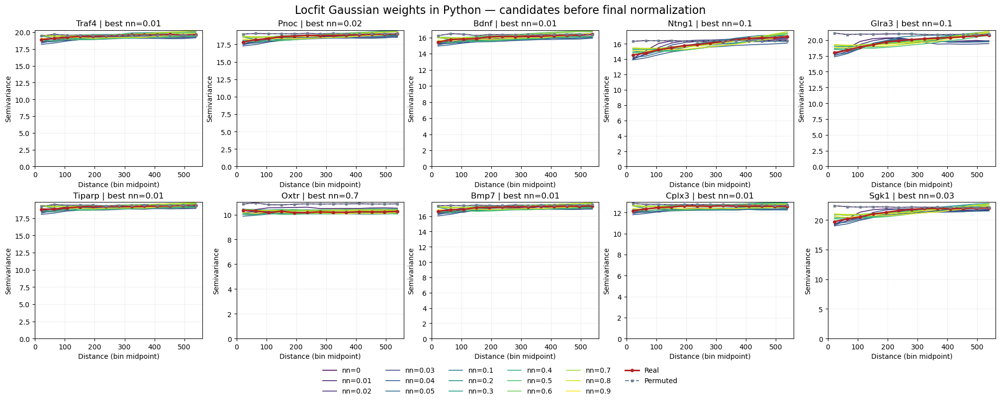

Python adaptive Gaussian smoothing on all 6,110 cells; same 4,665,748 pairs and 13 bins; max.dist=560.386660.


nn,0.00,0.01,0.02,0.03,0.04,0.05,0.10,0.20,0.30,0.40,0.50,0.60,0.70,0.80,0.90
Traf4,0.882163,0.355682,0.431587,1.979632,3.951382,1.357406,0.407679,1.542824,0.915037,1.071906,1.952811,1.005732,0.548352,1.485550,0.702820
Pnoc,3.139569,0.404075,0.280396,1.889986,3.370984,1.625256,0.632342,1.627448,1.242862,1.032751,1.230905,1.320928,0.918982,1.254696,0.941148
Bdnf,2.001150,0.324810,0.610009,1.723145,3.427769,1.990925,0.419321,1.169631,0.639587,0.861996,1.408389,1.586059,1.031172,0.583850,0.488857
Ntng1,9.440528,2.747521,1.790351,1.056040,6.169332,1.903412,0.790381,0.820441,1.271417,1.656896,2.046551,1.560900,1.442296,2.157330,2.100055
Glra3,27.512039,5.032295,4.188366,7.559918,4.109287,4.012688,1.639537,1.921103,3.026185,2.256264,4.323502,2.952375,2.969580,3.585663,2.982970
Tiparp,0.940985,0.242982,0.663798,1.983007,3.027601,1.154051,0.335451,0.961880,1.009532,0.640879,1.745535,0.897053,0.415565,0.997839,0.462107
Oxtr,5.200164,1.214964,0.296749,0.156561,0.609352,0.266306,0.199858,0.326903,0.422936,0.187289,0.501796,0.370506,0.128511,0.194864,0.165109
Bmp7,1.502060,0.193421,0.408623,1.595491,2.318870,1.144155,0.352080,0.938152,0.977369,0.786472,1.673722,0.986657,0.487788,1.048780,0.588833
Cplx3,0.970276,0.045333,0.543910,1.318208,1.704201,1.656621,0.420537,0.420947,0.792997,0.392360,0.937423,0.566397,0.354322,0.446646,0.447500
Sgk1,17.145212,2.499996,1.827912,1.166855,4.515375,3.393326,1.540600,3.454441,3.314332,3.037434,3.338552,2.866477,3.181337,3.869469,3.382536


In [4]:
# Python adaptive Gaussian kernel smoothing on the original irregular coordinates.
# For nn>0, h_i is the distance from cell i to its ceil(nn*(N-1))-th
# other cell. The fitted degree-zero field is a normalized weighted average.
# locfit Gaussian convention: sigma_i = h_i / 2.5.
# nn=0 is the identity/no-smoothing candidate.
from scipy.spatial.distance import cdist
from threadpoolctl import threadpool_limits

nn_candidates = np.r_[0.0, 0.01, 0.02, 0.03, 0.04, 0.05, np.arange(1, 10, dtype=float) / 10]
n_cells, n_genes = log_cpm.shape
positive = np.flatnonzero(nn_candidates > 0)
neighbor_counts = np.ceil(nn_candidates[positive] * (n_cells - 1)).astype(int)
candidate_raw = np.empty((len(nn_candidates), n_cells, n_genes), dtype=float)
candidate_raw[0] = permuted_log_cpm

# Block pairwise distances to keep memory bounded.
block_size = 256
LOCFIT_GAUSSIAN_FACTOR = 2.5
with threadpool_limits(limits=1):
    for start in range(0, n_cells, block_size):
        stop = min(start + block_size, n_cells)
        distance2 = cdist(coords[start:stop], coords, metric="sqeuclidean")
        kth_distance2 = np.partition(distance2, neighbor_counts, axis=1)[:, neighbor_counts]
        if np.any(kth_distance2 <= 0):
            raise ValueError("A bandwidth is zero; check for duplicate coordinates.")
        for local_k, candidate_k in enumerate(positive):
            weights = np.exp(
                -0.5 * LOCFIT_GAUSSIAN_FACTOR**2
                * distance2 / kth_distance2[:, local_k, None]
            )
            weights /= weights.sum(axis=1, keepdims=True)
            candidate_raw[candidate_k, start:stop] = weights @ permuted_log_cpm

candidate_raw_variograms = np.stack([classical_variogram(field) for field in candidate_raw])
np.testing.assert_allclose(candidate_raw_variograms[0], variogram_permuted, equal_nan=True)
# Keep nn=0 as the literal permutation baseline.
candidate_matched = candidate_raw.copy()
candidate_variograms = candidate_raw_variograms.copy()
fit_coefficients = np.full((len(nn_candidates), n_genes, 2), np.nan)
fit_coefficients[0, :, :] = (0.0, 1.0)  # Identity baseline; no regression.
candidate_sse = np.empty((len(nn_candidates), n_genes))
for j in range(n_genes):
    noise_rng = np.random.default_rng(1)
    for k in range(1, len(nn_candidates)):
        design = np.column_stack((np.ones(valid_bins.sum()), candidate_raw_variograms[k, valid_bins, j]))
        beta, _, rank, _ = np.linalg.lstsq(design, variogram_real[valid_bins, j], rcond=None)
        if rank < 2:
            raise ValueError(f"Singular variogram fit: {selected_genes[j]}, nn={nn_candidates[k]}")
        fit_coefficients[k, j] = beta
        candidate_matched[k, :, j] = (
            np.sqrt(abs(beta[1])) * candidate_raw[k, :, j]
            + np.sqrt(abs(beta[0])) * noise_rng.standard_normal(n_cells)
        )
for k, field in enumerate(candidate_matched):
    if k > 0:
        candidate_variograms[k] = classical_variogram(field)
    candidate_sse[k] = np.sum((candidate_variograms[k, valid_bins] - variogram_real[valid_bins]) ** 2, axis=0)

best_indices = np.argmin(candidate_sse, axis=0)
best_nn = nn_candidates[best_indices]
best_raw = np.column_stack([candidate_raw[k, :, j] for j, k in enumerate(best_indices)])
best_matched_before_normalization = np.column_stack([candidate_matched[k, :, j] for j, k in enumerate(best_indices)])
best_variograms_before_normalization = np.column_stack([candidate_variograms[k, :, j] for j, k in enumerate(best_indices)])
np.testing.assert_allclose(
    classical_variogram(best_matched_before_normalization),
    best_variograms_before_normalization, equal_nan=True,
)
np.testing.assert_array_equal(candidate_matched[0], permuted_log_cpm)

fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
colors = plt.colormaps["viridis"](np.linspace(0, 1, len(nn_candidates)))
for j, (ax, gene) in enumerate(zip(axes.flat, selected_genes)):
    for k, nn in enumerate(nn_candidates):
        ax.plot(lag_centers, candidate_variograms[k, :, j], color=colors[k], linewidth=1.2, label=f"nn={nn:g}")
    ax.plot(lag_centers, variogram_real[:, j], "o-", color="firebrick", linewidth=2.2, markersize=4, label="Real")
    ax.plot(lag_centers, variogram_permuted[:, j], "s--", color="slategray", markersize=3, label="Permuted")
    ax.set(title=f"{gene} | best nn={best_nn[j]:g}", xlabel="Distance (bin midpoint)", ylabel="Semivariance", xlim=(0, max_dist))
    ax.set_ylim(bottom=0); ax.grid(alpha=0.2)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=6, frameon=False)
fig.suptitle("Locfit Gaussian weights in Python — candidates before final normalization", fontsize=16)
plt.show()
matching_scores = pd.DataFrame(candidate_sse.T, index=selected_genes, columns=pd.Index(nn_candidates, name="nn"))
print(f"Python adaptive Gaussian smoothing on all {n_cells:,} cells; same {len(pairs):,} pairs and {N_BINS} bins; max.dist={max_dist:.6f}.")
display(matching_scores)


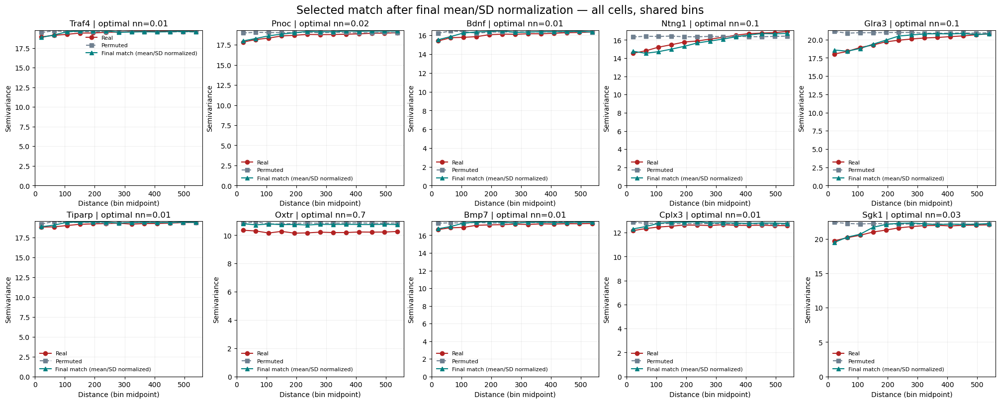

,gene,optimal_nn,selection_SSE,final_SSE,final_scale,real_mean,final_mean,real_std,final_std,intercept,slope
0,Traf4,0.01,0.355682,0.358616,1.002650,4.233770,4.233770,4.424123,4.424123,18.762532,1.618517
1,Pnoc,0.02,0.280396,1.109434,1.010921,4.223178,4.223178,4.362026,4.362026,17.798434,4.195625
2,Bdnf,0.01,0.324810,0.927574,1.009355,2.889530,2.889530,4.047349,4.047349,15.202424,2.434606
3,Ntng1,0.10,0.790381,1.073413,0.988460,2.753320,2.753320,4.046051,4.046051,14.784757,44.737878
4,Glra3,0.10,1.639537,1.831723,1.000669,5.224906,5.224906,4.573345,4.573345,18.124640,125.398541
5,Tiparp,0.01,0.242982,0.483287,1.006162,4.322562,4.322562,4.403312,4.403312,18.616669,1.224106
6,Oxtr,0.70,0.128511,3.813123,1.021956,1.579905,1.579905,3.291333,3.291333,10.236104,-25.195215
7,Bmp7,0.01,0.193421,0.807428,1.007781,3.153819,3.153819,4.179344,4.179344,16.501720,1.588567
8,Cplx3,0.01,0.045333,0.621367,1.009046,2.082656,2.082656,3.584579,3.584579,12.082913,1.647354
9,Sgk1,0.03,1.166855,2.166016,1.009347,6.112323,6.112323,4.726252,4.726252,19.599166,11.783418


In [5]:
# Normalize only after selecting nn; retain the original matching objective.
target_mean = log_cpm.mean(axis=0)
target_std = log_cpm.std(axis=0, ddof=0)
matched_mean = best_matched_before_normalization.mean(axis=0)
matched_std = best_matched_before_normalization.std(axis=0, ddof=0)
if np.any(matched_std <= 0):
    raise ValueError("Cannot normalize a constant matched field.")
final_scale = target_std / matched_std
best_matched = (
    target_mean
    + (best_matched_before_normalization - matched_mean) * final_scale
)
# Preserve the nn=0 permutation exactly, including floating-point values.
identity_genes = best_nn == 0
best_matched[:, identity_genes] = permuted_log_cpm[:, identity_genes]
final_scale[identity_genes] = 1.0
best_variograms = classical_variogram(best_matched)
final_sse = np.sum(
    (best_variograms[valid_bins] - variogram_real[valid_bins])**2, axis=0
)
np.testing.assert_allclose(best_matched.mean(axis=0), target_mean, atol=1e-12)
np.testing.assert_allclose(best_matched.std(axis=0), target_std, atol=1e-12)
np.testing.assert_allclose(
    best_variograms,
    best_variograms_before_normalization * final_scale**2,
    equal_nan=True,
)

# Best fitted candidate only, with the unchanged real and permuted references.
fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
for j, (ax, gene) in enumerate(zip(axes.flat, selected_genes)):
    ax.plot(lag_centers, variogram_real[:, j], "o-", color="firebrick", label="Real")
    ax.plot(lag_centers, variogram_permuted[:, j], "s--",
            color="slategray", label="Permuted")
    ax.plot(lag_centers, best_variograms[:, j], "^-",
            color="teal", label="Final match (mean/SD normalized)")
    ax.set(title=f"{gene} | optimal nn={best_nn[j]:g}",
           xlabel="Distance (bin midpoint)", ylabel="Semivariance",
           xlim=(0, max_dist))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Selected match after final mean/SD normalization — all cells, shared bins", fontsize=16)
plt.show()
best_match_summary = pd.DataFrame({
    "gene": selected_genes, "optimal_nn": best_nn,
    "selection_SSE": candidate_sse[best_indices, np.arange(n_genes)],
    "final_SSE": final_sse,
    "final_scale": final_scale,
    "real_mean": target_mean,
    "final_mean": best_matched.mean(axis=0),
    "real_std": target_std,
    "final_std": best_matched.std(axis=0),
    "intercept": fit_coefficients[best_indices, np.arange(n_genes), 0],
    "slope": fit_coefficients[best_indices, np.arange(n_genes), 1],
})
display(best_match_summary)


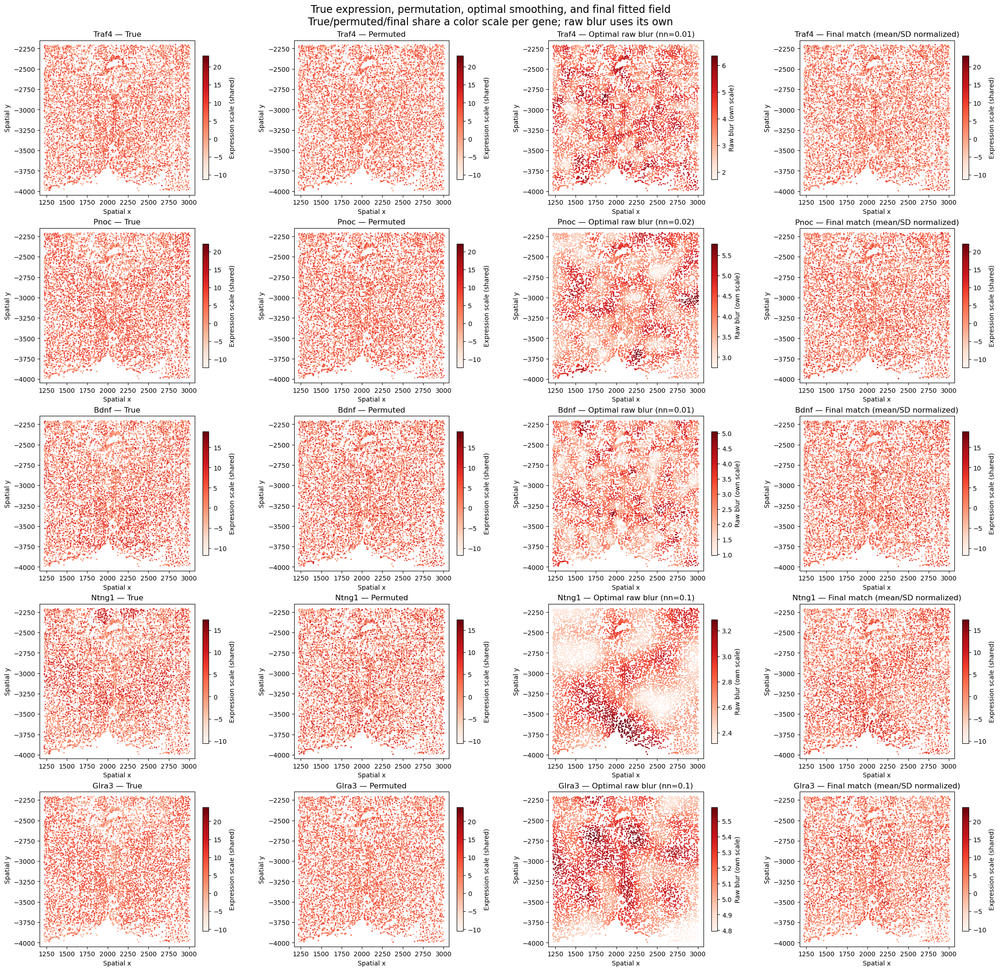

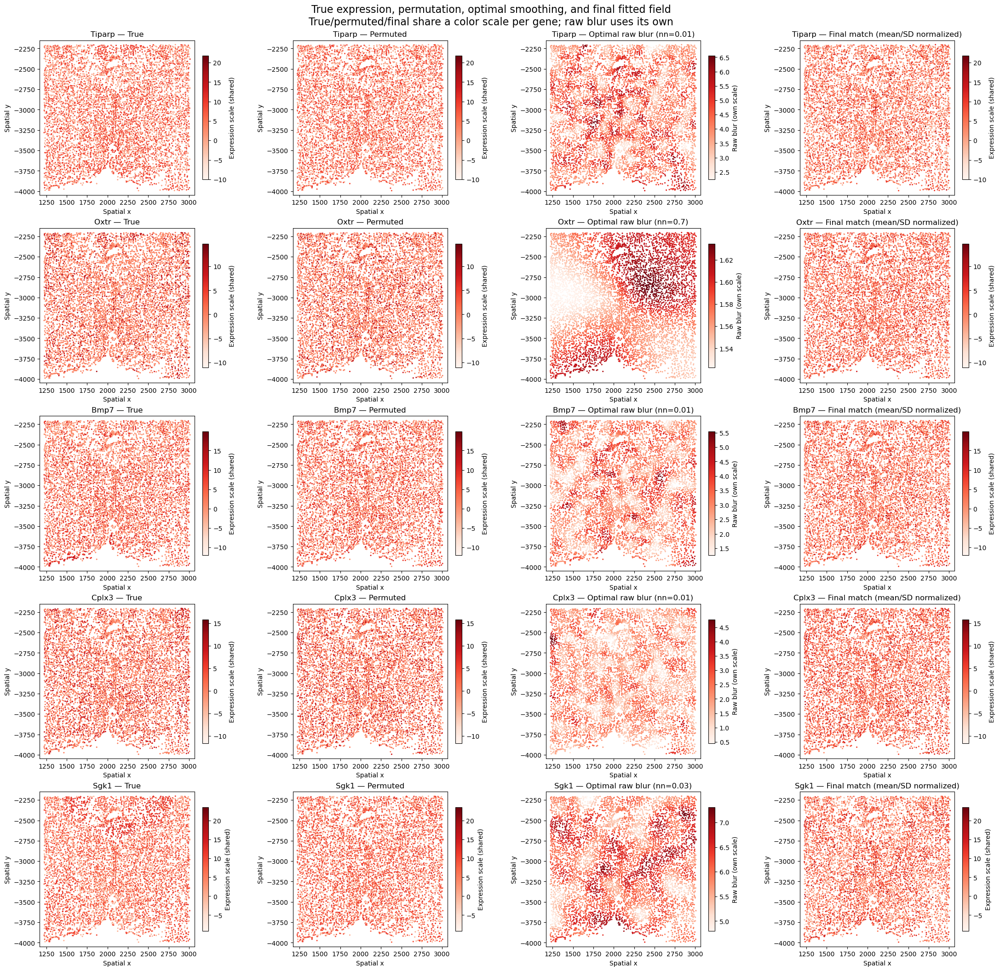

In [6]:
# Compare true/permuted/final fields on a shared per-gene color scale.
# The unnormalized raw blur retains a separate scale for diagnosis.
spatial_min = coords.min(axis=0)
spatial_max = coords.max(axis=0)
spatial_pad = 0.03 * (spatial_max - spatial_min)
for start in range(0, n_genes, 5):
    gene_indices = range(start, min(start + 5, n_genes))
    fig, axes = plt.subplots(
        len(gene_indices), 4, figsize=(22, 4.2 * len(gene_indices)),
        constrained_layout=True, squeeze=False,
    )
    for row, j in enumerate(gene_indices):
        fields = (log_cpm[:, j], permuted_log_cpm[:, j], best_raw[:, j], best_matched[:, j])
        labels = ("True", "Permuted", f"Optimal raw blur (nn={best_nn[j]:g})",
                  "Final match (mean/SD normalized)")
        shared_min = min(float(fields[k].min()) for k in (0, 1, 3))
        shared_max = max(float(fields[k].max()) for k in (0, 1, 3))
        for column, (ax, field, label) in enumerate(zip(axes[row], fields, labels)):
            vmin, vmax = (
                (float(field.min()), float(field.max())) if column == 2
                else (shared_min, shared_max)
            )
            if vmax <= vmin:
                vmax = vmin + 1e-12
            points = ax.scatter(
                coords[:, 0], coords[:, 1], c=field, cmap="Reds",
                vmin=vmin, vmax=vmax, s=5, linewidths=0, rasterized=True,
            )
            ax.set(title=f"{selected_genes[j]} — {label}",
                   xlabel="Spatial x", ylabel="Spatial y",
                   xlim=(spatial_min[0] - spatial_pad[0], spatial_max[0] + spatial_pad[0]),
                   ylim=(spatial_min[1] - spatial_pad[1], spatial_max[1] + spatial_pad[1]))
            ax.set_aspect("equal", adjustable="box")
            fig.colorbar(points, ax=ax, shrink=0.8, pad=0.025,
                         label="Raw blur (own scale)" if column == 2 else "Expression scale (shared)")
    fig.suptitle(
        "True expression, permutation, optimal smoothing, and final fitted field\n"
        "True/permuted/final share a color scale per gene; raw blur uses its own", fontsize=16,
    )
    plt.show()


## Uniform Gaussian bandwidth analysis

This section repeats the matching analysis with a **uniform** spatial bandwidth rather than an adaptive bandwidth. Let \(d\) be the median distance from each retained cell to its nearest other cell. The candidate locfit bandwidths are \([d,2d,3d,4d,6d,8d,12d]\). Every target cell uses the same bandwidth for a candidate, while the permutation remains the same as above. Since the corrected locfit Gaussian convention uses \(\exp[-(2.5r/h)^2/2]\), the listed values are treated as the bandwidth parameter \(h\); the `2.5` factor is retained. The permutation variogram is shown as the unsmoothed reference, but is not included as one of these positive-bandwidth candidates.

As in the adaptive section, each candidate is variogram-matched first, the best bandwidth is selected by the empirical variogram SSE, and only then is the selected field shifted and scaled to the real gene's mean and standard deviation. The final variogram and maps are recomputed after that normalization.


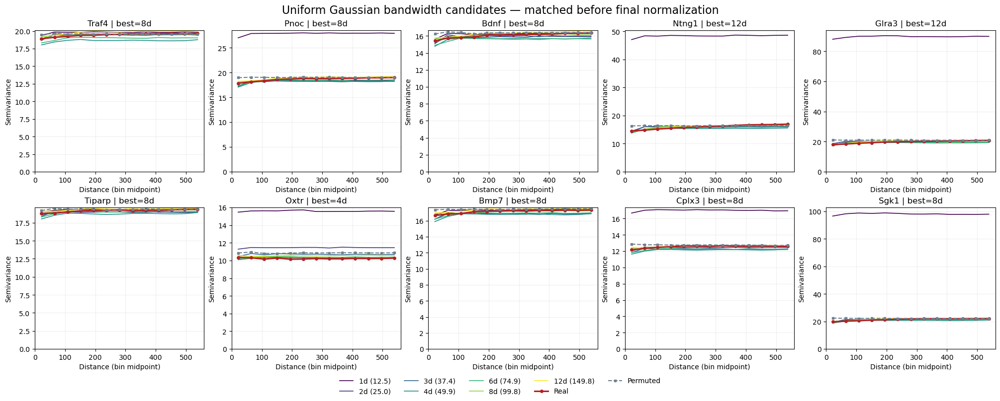

Uniform Gaussian base d = median nearest-neighbor distance = 12.479481; locfit factor = 2.5.


bandwidth / d,1.0,2.0,3.0,4.0,6.0,8.0,12.0
Traf4,2.029934,0.323678,0.644234,9.588129,3.472511,0.244328,2.014145
Pnoc,1103.960829,2.581986,4.054097,4.288942,1.616175,0.275140,0.921950
Bdnf,0.708090,1.031950,0.795778,3.057259,3.563962,0.194278,0.794282
Ntng1,13648.149302,4.740254,5.289843,10.798143,5.449128,2.328552,1.015448
Glra3,63531.936142,7.210131,10.885041,11.736973,7.260004,4.046700,3.379953
Tiparp,0.411703,0.847805,1.135386,3.207794,0.811167,0.150036,0.668801
Oxtr,373.252302,19.373130,2.851277,0.229306,0.373424,1.237828,1.377916
Bmp7,0.488476,1.552225,1.667165,2.768499,1.142162,0.142727,0.743989
Cplx3,258.832971,0.265030,1.285197,2.412235,1.726254,0.107419,0.172435
Sgk1,76329.148046,5.056898,4.546158,12.176262,4.162027,1.864026,1.896227


In [7]:
# Uniform Gaussian smoothing and the same variogram-matching pipeline.
# d is the median nearest-neighbor distance in the original coordinate units.
from scipy.spatial.distance import cdist

nearest_distances = cKDTree(coords).query(coords, k=2)[0][:, 1]
uniform_base_bandwidth = float(np.median(nearest_distances))
uniform_multipliers = np.array([1., 2., 3., 4., 6., 8., 12.])
uniform_bandwidths = uniform_base_bandwidth * uniform_multipliers
uniform_n_candidates = len(uniform_bandwidths)
uniform_raw = np.empty((uniform_n_candidates, n_cells, n_genes), dtype=float)

with threadpool_limits(limits=1):
    for start in range(0, n_cells, block_size):
        stop = min(start + block_size, n_cells)
        distance2 = cdist(coords[start:stop], coords, metric="sqeuclidean")
        for k, bandwidth in enumerate(uniform_bandwidths):
            weights = np.exp(
                -0.5 * LOCFIT_GAUSSIAN_FACTOR**2
                * distance2 / bandwidth**2
            )
            weights /= weights.sum(axis=1, keepdims=True)
            uniform_raw[k, start:stop] = weights @ permuted_log_cpm

uniform_raw_variograms = np.stack([
    classical_variogram(field) for field in uniform_raw
])
uniform_matched_before_normalization = uniform_raw.copy()
uniform_variograms_before_normalization = uniform_raw_variograms.copy()
uniform_fit_coefficients = np.empty((uniform_n_candidates, n_genes, 2))
uniform_candidate_sse = np.empty((uniform_n_candidates, n_genes))

for j in range(n_genes):
    noise_rng = np.random.default_rng(1)
    for k in range(uniform_n_candidates):
        design = np.column_stack((
            np.ones(valid_bins.sum()),
            uniform_raw_variograms[k, valid_bins, j],
        ))
        beta, _, rank, _ = np.linalg.lstsq(
            design, variogram_real[valid_bins, j], rcond=None
        )
        if rank < 2:
            raise ValueError(
                f"Singular variogram fit: {selected_genes[j]}, "
                f"bandwidth={uniform_bandwidths[k]:.6f}"
            )
        uniform_fit_coefficients[k, j] = beta
        uniform_matched_before_normalization[k, :, j] = (
            np.sqrt(abs(beta[1])) * uniform_raw[k, :, j]
            + np.sqrt(abs(beta[0])) * noise_rng.standard_normal(n_cells)
        )

uniform_variograms_before_normalization = np.stack([
    classical_variogram(field)
    for field in uniform_matched_before_normalization
])
uniform_candidate_sse = np.sum(
    (uniform_variograms_before_normalization[:, valid_bins] - variogram_real[valid_bins])**2,
    axis=1,
)
uniform_best_indices = np.argmin(uniform_candidate_sse, axis=0)
uniform_best_multiplier = uniform_multipliers[uniform_best_indices]
uniform_best_bandwidth = uniform_bandwidths[uniform_best_indices]
uniform_best_raw = np.column_stack([
    uniform_raw[k, :, j]
    for j, k in enumerate(uniform_best_indices)
])
uniform_best_matched_before_normalization = np.column_stack([
    uniform_matched_before_normalization[k, :, j]
    for j, k in enumerate(uniform_best_indices)
])
uniform_best_variograms_before_normalization = np.column_stack([
    uniform_variograms_before_normalization[k, :, j]
    for j, k in enumerate(uniform_best_indices)
])

# Apply the requested final mean/SD normalization only after bandwidth selection.
uniform_target_mean = log_cpm.mean(axis=0)
uniform_target_std = log_cpm.std(axis=0, ddof=0)
uniform_matched_mean = uniform_best_matched_before_normalization.mean(axis=0)
uniform_matched_std = uniform_best_matched_before_normalization.std(axis=0, ddof=0)
if np.any(uniform_matched_std <= 0):
    raise ValueError("Cannot normalize a constant uniform matched field.")
uniform_final_scale = uniform_target_std / uniform_matched_std
uniform_best_matched = (
    uniform_target_mean
    + (uniform_best_matched_before_normalization - uniform_matched_mean)
    * uniform_final_scale
)
uniform_best_variograms = classical_variogram(uniform_best_matched)
uniform_final_sse = np.sum(
    (uniform_best_variograms[valid_bins] - variogram_real[valid_bins])**2,
    axis=0,
)
np.testing.assert_allclose(
    uniform_best_matched.mean(axis=0), uniform_target_mean, atol=1e-12
)
np.testing.assert_allclose(
    uniform_best_matched.std(axis=0), uniform_target_std, atol=1e-12
)
np.testing.assert_allclose(
    uniform_best_variograms,
    uniform_best_variograms_before_normalization * uniform_final_scale**2,
    equal_nan=True,
)

fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
colors = plt.colormaps["viridis"](
    np.linspace(0, 1, uniform_n_candidates)
)
for j, (ax, gene) in enumerate(zip(axes.flat, selected_genes)):
    for k, (multiplier, bandwidth) in enumerate(
        zip(uniform_multipliers, uniform_bandwidths)
    ):
        ax.plot(
            lag_centers, uniform_variograms_before_normalization[k, :, j],
            color=colors[k], linewidth=1.2,
            label=f"{multiplier:g}d ({bandwidth:.1f})",
        )
    ax.plot(
        lag_centers, variogram_real[:, j], "o-", color="firebrick",
        linewidth=2.2, markersize=4, label="Real",
    )
    ax.plot(
        lag_centers, variogram_permuted[:, j], "s--", color="slategray",
        markersize=3, label="Permuted",
    )
    ax.set(
        title=f"{gene} | best={uniform_best_multiplier[j]:g}d",
        xlabel="Distance (bin midpoint)", ylabel="Semivariance",
        xlim=(0, max_dist),
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5, frameon=False)
fig.suptitle(
    "Uniform Gaussian bandwidth candidates — matched before final normalization",
    fontsize=16,
)
plt.show()
uniform_matching_scores = pd.DataFrame(
    uniform_candidate_sse.T,
    index=selected_genes,
    columns=pd.Index(uniform_multipliers, name="bandwidth / d"),
)
print(
    f"Uniform Gaussian base d = median nearest-neighbor distance = "
    f"{uniform_base_bandwidth:.6f}; locfit factor = "
    f"{LOCFIT_GAUSSIAN_FACTOR:g}."
)
display(uniform_matching_scores)


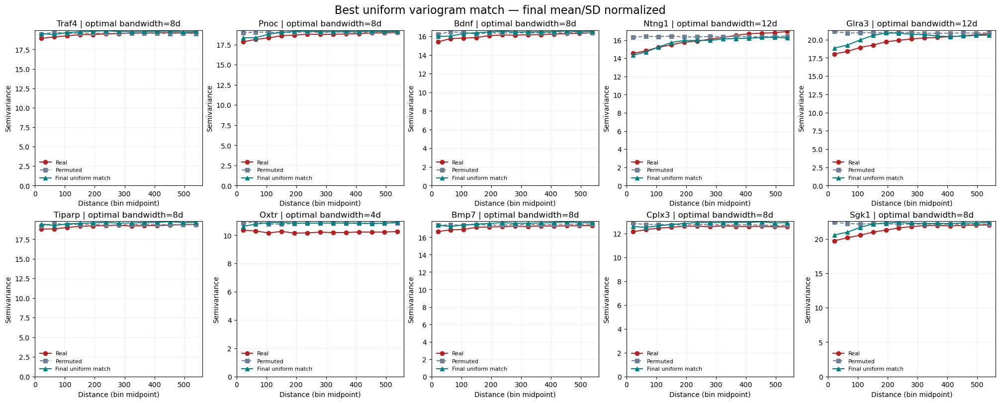

,gene,optimal_multiplier,bandwidth,selection_SSE,final_SSE,final_scale,real_mean,final_mean,real_std,final_std,intercept,slope
0,Traf4,8.0,99.835848,0.244328,1.406282,1.007372,4.233770,4.233770,4.424123,4.424123,18.774481,1.593212
1,Pnoc,8.0,99.835848,0.275140,1.548638,1.006109,4.223178,4.223178,4.362026,4.362026,17.608005,2.464448
2,Bdnf,8.0,99.835848,0.194278,1.755778,1.010385,2.889530,2.889530,4.047349,4.047349,15.224681,2.391121
3,Ntng1,12.0,149.753772,1.015448,1.559311,0.992429,2.753320,2.753320,4.046051,4.046051,14.122256,13.022656
4,Glra3,12.0,149.753772,3.379953,7.327469,1.012899,5.224906,5.224906,4.573345,4.573345,17.863134,11.468452
5,Tiparp,8.0,99.835848,0.150036,2.178340,1.009001,4.322562,4.322562,4.403312,4.403312,18.626219,1.191904
6,Oxtr,4.0,49.917924,0.229306,5.138115,1.026269,1.579905,1.579905,3.291333,3.291333,10.457885,-0.213494
7,Bmp7,8.0,99.835848,0.142727,2.471296,1.012926,3.153819,3.153819,4.179344,4.179344,16.509146,1.573819
8,Cplx3,8.0,99.835848,0.107419,1.298904,1.009991,2.082656,2.082656,3.584579,3.584579,12.090585,1.571499
9,Sgk1,8.0,99.835848,1.864026,6.678889,1.018919,6.112323,6.112323,4.726252,4.726252,19.187169,4.459780


In [8]:
# Best uniform-bandwidth match after final mean/SD normalization.
fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
for j, (ax, gene) in enumerate(zip(axes.flat, selected_genes)):
    ax.plot(
        lag_centers, variogram_real[:, j], "o-", color="firebrick",
        label="Real",
    )
    ax.plot(
        lag_centers, variogram_permuted[:, j], "s--", color="slategray",
        label="Permuted",
    )
    ax.plot(
        lag_centers, uniform_best_variograms[:, j], "^-", color="teal",
        label="Final uniform match",
    )
    ax.set(
        title=f"{gene} | optimal bandwidth={uniform_best_multiplier[j]:g}d",
        xlabel="Distance (bin midpoint)", ylabel="Semivariance",
        xlim=(0, max_dist),
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle(
    "Best uniform variogram match — final mean/SD normalized",
    fontsize=16,
)
plt.show()

uniform_best_match_summary = pd.DataFrame({
    "gene": selected_genes,
    "optimal_multiplier": uniform_best_multiplier,
    "bandwidth": uniform_best_bandwidth,
    "selection_SSE": uniform_candidate_sse[
        uniform_best_indices, np.arange(n_genes)
    ],
    "final_SSE": uniform_final_sse,
    "final_scale": uniform_final_scale,
    "real_mean": uniform_target_mean,
    "final_mean": uniform_best_matched.mean(axis=0),
    "real_std": uniform_target_std,
    "final_std": uniform_best_matched.std(axis=0),
    "intercept": uniform_fit_coefficients[
        uniform_best_indices, np.arange(n_genes), 0
    ],
    "slope": uniform_fit_coefficients[
        uniform_best_indices, np.arange(n_genes), 1
    ],
})
display(uniform_best_match_summary)


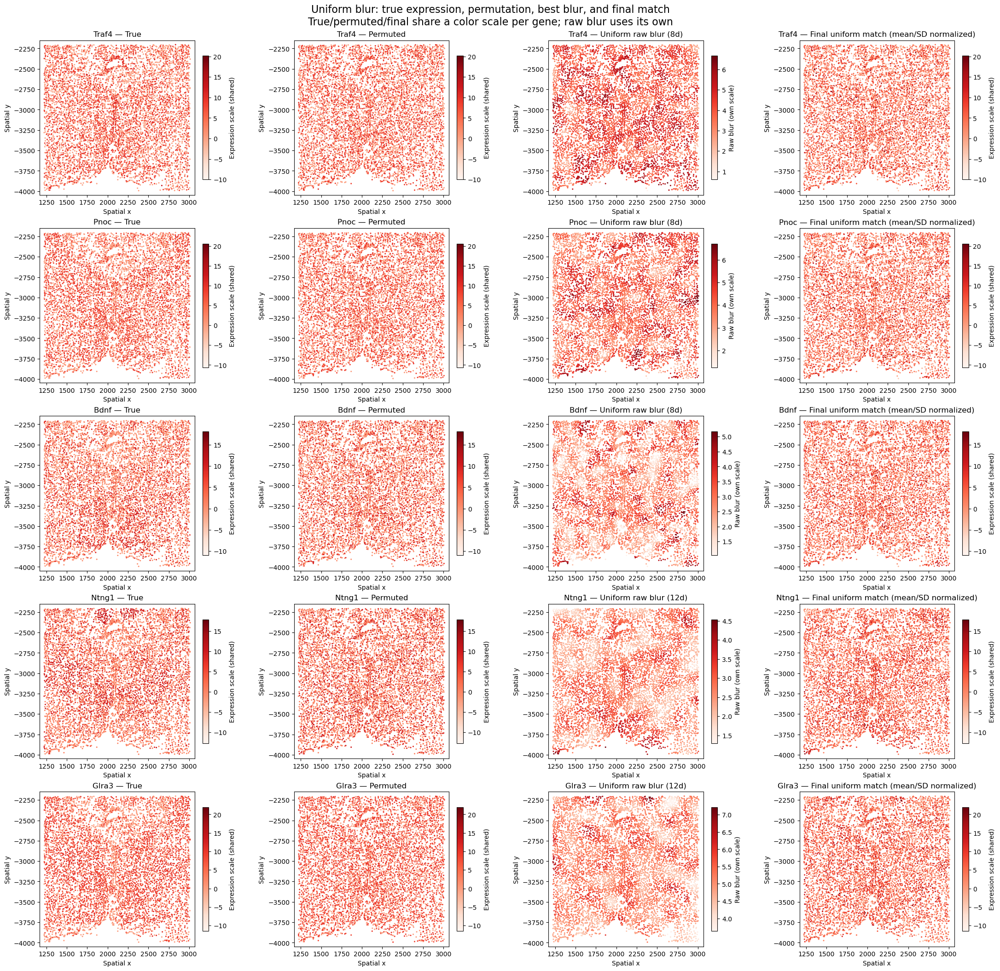

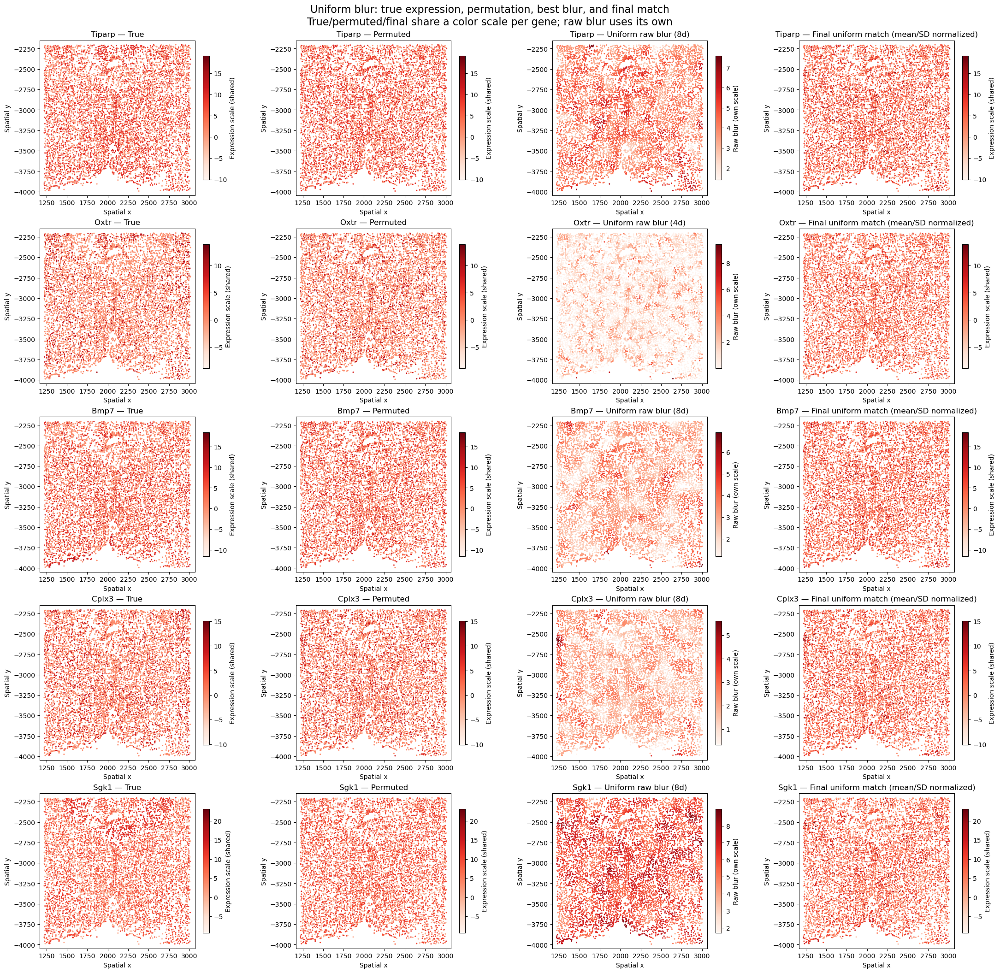

In [9]:
# Spatial maps for the uniform-bandwidth result.
for start in range(0, n_genes, 5):
    gene_indices = range(start, min(start + 5, n_genes))
    fig, axes = plt.subplots(
        len(gene_indices), 4, figsize=(22, 4.2 * len(gene_indices)),
        constrained_layout=True, squeeze=False,
    )
    for row, j in enumerate(gene_indices):
        fields = (
            log_cpm[:, j], permuted_log_cpm[:, j],
            uniform_best_raw[:, j], uniform_best_matched[:, j],
        )
        labels = (
            "True", "Permuted",
            f"Uniform raw blur ({uniform_best_multiplier[j]:g}d)",
            "Final uniform match (mean/SD normalized)",
        )
        shared_min = min(float(fields[k].min()) for k in (0, 1, 3))
        shared_max = max(float(fields[k].max()) for k in (0, 1, 3))
        for column, (ax, field, label) in enumerate(
            zip(axes[row], fields, labels)
        ):
            vmin, vmax = (
                (float(field.min()), float(field.max()))
                if column == 2 else (shared_min, shared_max)
            )
            if vmax <= vmin:
                vmax = vmin + 1e-12
            points = ax.scatter(
                coords[:, 0], coords[:, 1], c=field, cmap="Reds",
                vmin=vmin, vmax=vmax, s=5, linewidths=0,
                rasterized=True,
            )
            ax.set(
                title=f"{selected_genes[j]} — {label}",
                xlabel="Spatial x", ylabel="Spatial y",
                xlim=(spatial_min[0] - spatial_pad[0],
                      spatial_max[0] + spatial_pad[0]),
                ylim=(spatial_min[1] - spatial_pad[1],
                      spatial_max[1] + spatial_pad[1]),
            )
            ax.set_aspect("equal", adjustable="box")
            fig.colorbar(
                points, ax=ax, shrink=0.8, pad=0.025,
                label=("Raw blur (own scale)" if column == 2
                       else "Expression scale (shared)"),
            )
    fig.suptitle(
        "Uniform blur: true expression, permutation, best blur, and final match\n"
        "True/permuted/final share a color scale per gene; raw blur uses its own",
        fontsize=16,
    )
    plt.show()
